# 03 NYC Property Sales: Exploratory Analysis

This notebook investigates patterns in the cleaned NYC property sales dataset using summary tables, comparisons, and selected visualizations.

**Focus:** transaction activity over time, property-type composition, cash-based sale prices, and differences across boroughs and neighborhoods.

**Analysis rules**
- Include all recorded transactions when measuring activity, including `$0` sale-price records.
- Use only `SALE PRICE > 0` for median sale-price and cash-value comparisons.
- Use median sale price to reduce the influence of highly skewed transaction values.
- Apply the 500-positive-price-transaction threshold only to selected neighborhood and property-type comparisons.
- Describe associations, not causes. The dataset records property transactions, not unique buyers or buyer intent.

The notebook is exploratory: it documents how the patterns were examined. The Power BI report presents the selected findings in an interactive format.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/nyc_sales_property_cleaned.csv")

df["SALE DATE"] = pd.to_datetime(df["SALE DATE"], errors="coerce")
df["SALE YEAR"] = df["SALE DATE"].dt.year
df["PROPERTY AGE"] = df["SALE YEAR"] - df["YEAR BUILT"]

positive_sales = df[df["SALE PRICE"] > 0].copy()

borough_names = {
    1: "Manhattan",
    2: "Bronx",
    3: "Brooklyn",
    4: "Queens",
    5: "Staten Island"
}
df["BOROUGH NAME"] = df["BOROUGH"].map(borough_names)
positive_sales["BOROUGH NAME"] = positive_sales["BOROUGH"].map(borough_names)

print("Dataset shape:", df.shape)
print("Date range:", df["SALE YEAR"].min(), "to", df["SALE YEAR"].max())
print("Unique boroughs:", df["BOROUGH NAME"].nunique())
print("Positive-price transactions:", len(positive_sales))

Dataset shape: (842256, 23)
Date range: 2016 to 2025
Unique boroughs: 5
Positive-price transactions: 582307


## 1. Transaction Activity

First, measure overall sales activity by year, borough, and neighborhood.

These analyses use **all recorded transactions**, including `$0` sale-price records, because `$0` records represent ownership transfers and are relevant to transaction activity.

In [2]:
sales_by_year = (
    df.groupby("SALE YEAR")
    .size()
    .reset_index(name="TRANSACTION COUNT")
    .sort_values("SALE YEAR")
)

print("Transactions by year:")
print(sales_by_year.to_string(index=False))


sales_by_borough = (
    df.groupby("BOROUGH NAME")
    .size()
    .reset_index(name="TRANSACTION COUNT")
    .sort_values("TRANSACTION COUNT", ascending=False)
)

print("\nTransactions by borough:")
print(sales_by_borough.to_string(index=False))


sales_by_neighborhood = (
    df.groupby("NEIGHBORHOOD")
    .size()
    .reset_index(name="TRANSACTION COUNT")
    .sort_values("TRANSACTION COUNT", ascending=False)
)

print("\nTop 20 neighborhoods by transaction count:")
print(sales_by_neighborhood.head(20).to_string(index=False))

Transactions by year:
 SALE YEAR  TRANSACTION COUNT
      2016              88502
      2017              87880
      2018              83166
      2019              82729
      2020              68684
      2021              98521
      2022              93427
      2023              76411
      2024              78243
      2025              84693

Transactions by borough:
 BOROUGH NAME  TRANSACTION COUNT
       Queens             263860
     Brooklyn             238876
    Manhattan             184661
Staten Island              83638
        Bronx              71221

Top 20 neighborhoods by transaction count:
           NEIGHBORHOOD  TRANSACTION COUNT
         FLUSHING-NORTH              28858
UPPER EAST SIDE (59-79)              18866
UPPER EAST SIDE (79-96)              16647
UPPER WEST SIDE (59-79)              16031
     BEDFORD STUYVESANT              13725
           BOROUGH PARK              13198
           MIDTOWN EAST              12046
                BAYSIDE             

## 2. Transaction Composition Over Time

Overall transaction counts do not show whether the types of properties represented in the records have changed. This section compares the composition of recorded transactions over time.

Because the dataset records property transactions rather than unique buyers, changes in property mix should be interpreted as changes in the transactions represented in the data—not as direct evidence of changing buyer preferences.

In [3]:
property_mix = (
    df.groupby(["SALE YEAR", "BUILDING CLASS CATEGORY"])
    .size()
    .reset_index(name="TRANSACTION_COUNT")
)

property_mix["YEAR_TOTAL"] = property_mix.groupby("SALE YEAR")["TRANSACTION_COUNT"].transform("sum")
property_mix["TRANSACTION_SHARE_PCT"] = property_mix["TRANSACTION_COUNT"] / property_mix["YEAR_TOTAL"] * 100

top_property_types = df["BUILDING CLASS CATEGORY"].value_counts().head(10).index
property_mix_top = (
    property_mix[property_mix["BUILDING CLASS CATEGORY"].isin(top_property_types)]
    .sort_values(["SALE YEAR", "TRANSACTION_SHARE_PCT"], ascending=[True, False])
)

print("Transaction mix for the 10 most common property types:")
print(property_mix_top.to_string(index=False))

Transaction mix for the 10 most common property types:
 SALE YEAR           BUILDING CLASS CATEGORY  TRANSACTION_COUNT  YEAR_TOTAL  TRANSACTION_SHARE_PCT
      2016           01 ONE FAMILY DWELLINGS              18503       88502              20.906872
      2016           02 TWO FAMILY DWELLINGS              16370       88502              18.496757
      2016    10 COOPS - ELEVATOR APARTMENTS              13329       88502              15.060677
      2016   13 CONDOS - ELEVATOR APARTMENTS              12629       88502              14.269734
      2016         03 THREE FAMILY DWELLINGS               4513       88502               5.099320
      2016    07 RENTALS - WALKUP APARTMENTS               3762       88502               4.250751
      2016      09 COOPS - WALKUP APARTMENTS               2791       88502               3.153601
      2016             04 TAX CLASS 1 CONDOS               1666       88502               1.882443
      2016                  44 CONDO PARKING          

## 3. Transaction Value Over Time

Transaction activity and cash-based transaction value are different measures. This section uses only positive-price transactions to compare yearly transaction counts and median sale prices.

In [6]:
value_by_year = (
    positive_sales
    .groupby("SALE YEAR")
    .agg(
        POSITIVE_PRICE_TRANSACTIONS=("SALE PRICE", "count"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median"),
        TOTAL_POSITIVE_SALE_VALUE=("SALE PRICE", "sum")
    )
    .reset_index()
    .sort_values("SALE YEAR")
)

print("Cash-based transaction value by year:")
print(value_by_year.to_string(index=False))

Cash-based transaction value by year:
 SALE YEAR  POSITIVE_PRICE_TRANSACTIONS  MEDIAN_SALE_PRICE  TOTAL_POSITIVE_SALE_VALUE
      2016                        61714           580000.0               102360118092
      2017                        62249           635000.0                88996396102
      2018                        58180           651680.0                95999979031
      2019                        57086           692410.0               116658012720
      2020                        45073           700000.0                89976475316
      2021                        72029           780000.0               136326542841
      2022                        67416           815000.0               156112099552
      2023                        51059           797500.0                94276233241
      2024                        52272           800000.0                97283050228
      2025                        55229           860000.0               174975939360


## 4. Property Type Activity and Transaction Value

Property types are compared using both transaction volume and median sale price.

For value analysis, only positive-price transactions are included. Categories with fewer than 500 positive-price transactions are excluded from the ranked comparison to reduce the influence of very small samples.

In [7]:
sales_by_property_type = (
    df.groupby("BUILDING CLASS CATEGORY")
    .size()
    .reset_index(name="TRANSACTION COUNT")
    .sort_values("TRANSACTION COUNT", ascending=False)
)

print("Top 20 property types by transaction count:")
print(sales_by_property_type.head(20).to_string(index=False))


property_type_value = (
    positive_sales
    .groupby("BUILDING CLASS CATEGORY")
    .agg(
        TRANSACTION_COUNT=("SALE PRICE", "count"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median")
    )
    .reset_index()
)

property_type_value_filtered = (
    property_type_value[
        property_type_value["TRANSACTION_COUNT"] >= 500
    ]
    .sort_values("MEDIAN_SALE_PRICE", ascending=False)
)

print("\nProperty types with at least 500 positive-price transactions:")
print(property_type_value_filtered.to_string(index=False))

Top 20 property types by transaction count:
          BUILDING CLASS CATEGORY  TRANSACTION COUNT
          01 ONE FAMILY DWELLINGS             186111
          02 TWO FAMILY DWELLINGS             157446
   10 COOPS - ELEVATOR APARTMENTS             131550
  13 CONDOS - ELEVATOR APARTMENTS             129278
        03 THREE FAMILY DWELLINGS              44264
   07 RENTALS - WALKUP APARTMENTS              29921
     09 COOPS - WALKUP APARTMENTS              26297
            04 TAX CLASS 1 CONDOS              16359
15 CONDOS - 2-10 UNIT RESIDENTIAL              14545
                 44 CONDO PARKING              13991
                   17 CONDO COOPS              11833
       05 TAX CLASS 1 VACANT LAND              11291
    12 CONDOS - WALKUP APARTMENTS               9391
               22 STORE BUILDINGS               8851
           14 RENTALS - 4-10 UNIT               6148
            29 COMMERCIAL GARAGES               5566
 08 RENTALS - ELEVATOR APARTMENTS               4501
  

In [8]:
print("Extreme property age records:")
print(
    df.loc[
        df["PROPERTY AGE"] > 200,
        [
            "BOROUGH",
            "NEIGHBORHOOD",
            "BUILDING CLASS CATEGORY",
            "YEAR BUILT",
            "SALE YEAR",
            "PROPERTY AGE",
            "SALE PRICE"
        ]
    ].sort_values("PROPERTY AGE", ascending=False).head(20)
)

print("\nExtreme sale price records:")
print(
    df.loc[
        df["SALE PRICE"] > 100_000_000,
        [
            "BOROUGH",
            "NEIGHBORHOOD",
            "BUILDING CLASS CATEGORY",
            "YEAR BUILT",
            "SALE YEAR",
            "PROPERTY AGE",
            "SALE PRICE"
        ]
    ].sort_values("SALE PRICE", ascending=False).head(20)
)

Extreme property age records:
        BOROUGH        NEIGHBORHOOD            BUILDING CLASS CATEGORY  \
370105        5         PRINCES BAY            01 ONE FAMILY DWELLINGS   
798656        1                SOHO             14 RENTALS - 4-10 UNIT   
782056        3          OCEAN HILL             14 RENTALS - 4-10 UNIT   
789180        1        CIVIC CENTER  15 CONDOS - 2-10 UNIT RESIDENTIAL   
774657        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
774658        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
774654        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
774653        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
789181        1        CIVIC CENTER  15 CONDOS - 2-10 UNIT RESIDENTIAL   
774659        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
774661        3  DOWNTOWN-METROTECH    13 CONDOS - ELEVATOR APARTMENTS   
774679        3  DOWNTOWN-METROTECH          43 CONDO OFFICE BUILDINGS   
774660  

## 5. Location and Transaction Value

Compare median sale prices across boroughs and neighborhoods.

The neighborhood comparison uses at least 500 positive-price transactions so that a small number of unusually expensive transactions does not dominate the ranking.

In [9]:
borough_value = (
    positive_sales
    .groupby("BOROUGH NAME")["SALE PRICE"]
    .median()
    .reset_index(name="MEDIAN SALE PRICE")
    .sort_values("MEDIAN SALE PRICE", ascending=False)
)

print("Median sale price by borough:")
print(borough_value.to_string(index=False))

neighborhood_value = (
    positive_sales
    .groupby("NEIGHBORHOOD")
    .agg(
        TRANSACTION_COUNT=("SALE PRICE", "count"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median")
    )
    .reset_index()
)

neighborhood_value_filtered = (
    neighborhood_value[
        neighborhood_value["TRANSACTION_COUNT"] >= 500
    ]
    .sort_values("MEDIAN_SALE_PRICE", ascending=False)
)

print("\nTop 20 neighborhoods by median sale price:")
print(neighborhood_value_filtered.head(20).to_string(index=False))

Median sale price by borough:
 BOROUGH NAME  MEDIAN SALE PRICE
    Manhattan          1200000.0
     Brooklyn           868000.0
       Queens           610000.0
Staten Island           558000.0
        Bronx           504033.0

Top 20 neighborhoods by median sale price:
             NEIGHBORHOOD  TRANSACTION_COUNT  MEDIAN_SALE_PRICE
            JAVITS CENTER                719          4250000.0
                     SOHO               3244          3075000.0
             CIVIC CENTER               1962          3043538.0
                  TRIBECA               4621          2500000.0
                  FASHION               1036          2275356.0
          CARROLL GARDENS               1543          2000000.0
                 FLATIRON               2897          1970000.0
              COBBLE HILL               1173          1950000.0
              MIDTOWN CBD               1877          1850000.0
              BOERUM HILL               1753          1725000.0
    DOWNTOWN-FULTON FERR

## 6. Property Characteristics: Unit Count and Age

These comparisons use positive-price transactions with valid values for the characteristic being analyzed. Results describe associations and should not be interpreted as proof that unit count or age alone determines sale price.

In [10]:
unit_value = positive_sales[
    positive_sales["TOTAL UNITS"] > 0
].copy()

unit_value["UNIT GROUP"] = pd.cut(
    unit_value["TOTAL UNITS"],
    bins=[0, 1, 2, 5, 10, float("inf")],
    labels=["1 Unit", "2 Units", "3-5 Units", "6-10 Units", "11+ Units"]
)

unit_value_summary = (
    unit_value
    .groupby("UNIT GROUP", observed=True)
    .agg(
        TRANSACTION_COUNT=("SALE PRICE", "count"),
        MEDIAN_UNITS=("TOTAL UNITS", "median"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median")
    )
    .reset_index()
)

print("\nSale price by total-unit group:")
print(unit_value_summary.to_string(index=False))


Sale price by total-unit group:
UNIT GROUP  TRANSACTION_COUNT  MEDIAN_UNITS  MEDIAN_SALE_PRICE
    1 Unit             274075           1.0           750000.0
   2 Units              92217           2.0           800000.0
 3-5 Units              36854           3.0          1090000.0
6-10 Units               8239           7.0          1830000.0
 11+ Units               8655          29.0          4675000.0


In [11]:
age_value = positive_sales[
    positive_sales["PROPERTY AGE"] >= 0
].copy()

age_value["AGE GROUP"] = pd.cut(
    age_value["PROPERTY AGE"],
    bins=[-1, 10, 25, 50, 100, float("inf")],
    labels=[
        "0-10 Years",
        "11-25 Years",
        "26-50 Years",
        "51-100 Years",
        "100+ Years"
    ]
)

age_value_summary = (
    age_value
    .groupby("AGE GROUP", observed=True)
    .agg(
        TRANSACTION_COUNT=("SALE PRICE", "count"),
        MEDIAN_AGE=("PROPERTY AGE", "median"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median")
    )
    .reset_index()
)

print("\nSale price by property-age group:")
print(age_value_summary.to_string(index=False))


Sale price by property-age group:
   AGE GROUP  TRANSACTION_COUNT  MEDIAN_AGE  MEDIAN_SALE_PRICE
  0-10 Years              59255         4.0           999000.0
 11-25 Years              41749        16.0           797500.0
 26-50 Years              47051        37.0           640000.0
51-100 Years             299648        78.0           640000.0
  100+ Years              93269       111.0           950000.0


## 7. Location × Property Type

Location and property type should not be viewed independently. The same property category can have substantially different transaction values across boroughs.

Only combinations with at least 500 positive-price transactions are included in the comparison.

In [12]:
location_property_value = (
    positive_sales
    .groupby(["BOROUGH NAME", "BUILDING CLASS CATEGORY"])
    .agg(
        TRANSACTION_COUNT=("SALE PRICE", "count"),
        MEDIAN_SALE_PRICE=("SALE PRICE", "median")
    )
    .reset_index()
)

location_property_value_filtered = (
    location_property_value[
        location_property_value["TRANSACTION_COUNT"] >= 500
    ]
    .sort_values("MEDIAN_SALE_PRICE", ascending=False)
)

print(
    location_property_value_filtered.head(25).to_string(index=False)
)

BOROUGH NAME           BUILDING CLASS CATEGORY  TRANSACTION_COUNT  MEDIAN_SALE_PRICE
   Manhattan               21 OFFICE BUILDINGS                799         18279000.0
    Brooklyn  08 RENTALS - ELEVATOR APARTMENTS                615         10360000.0
   Manhattan                22 STORE BUILDINGS                631          7500000.0
   Manhattan           01 ONE FAMILY DWELLINGS               1036          7000000.0
   Manhattan            14 RENTALS - 4-10 UNIT                518          5100000.0
   Manhattan    07 RENTALS - WALKUP APARTMENTS               3766          4500000.0
   Manhattan  08 RENTALS - ELEVATOR APARTMENTS               1415          4400000.0
   Manhattan          46 CONDO STORE BUILDINGS                722          3900000.0
   Manhattan           02 TWO FAMILY DWELLINGS                786          3800000.0
   Manhattan         43 CONDO OFFICE BUILDINGS               1212          3608131.0
      Queens                     30 WAREHOUSES                606

## 8. `$0` Sale-Price Records

The source documentation identifies `$0` sale-price records as ownership transfers without cash consideration. These records remain included in activity counts but are excluded from median sale-price and cash-value calculations.

This section measures how their count and share change over time.

In [13]:
zero_price_by_year = (
    df.groupby("SALE YEAR")
    .agg(
        TOTAL_TRANSACTIONS=("SALE PRICE", "count"),
        ZERO_PRICE_TRANSACTIONS=(
            "SALE PRICE",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

zero_price_by_year["ZERO_PRICE_PCT"] = (
    zero_price_by_year["ZERO_PRICE_TRANSACTIONS"]
    / zero_price_by_year["TOTAL_TRANSACTIONS"]
    * 100
)

print(zero_price_by_year.to_string(index=False))

 SALE YEAR  TOTAL_TRANSACTIONS  ZERO_PRICE_TRANSACTIONS  ZERO_PRICE_PCT
      2016               88502                    26788       30.268243
      2017               87880                    25631       29.165908
      2018               83166                    24986       30.043527
      2019               82729                    25643       30.996386
      2020               68684                    23611       34.376274
      2021               98521                    26492       26.889699
      2022               93427                    26011       27.840988
      2023               76411                    25352       33.178469
      2024               78243                    25971       33.192746
      2025               84693                    29464       34.789180


## 9. Selected Visualizations

The following charts provide visual support for selected patterns identified during exploratory analysis. Some findings are also presented in the Power BI dashboard. The focus here is on examining the data, checking patterns, and documenting observations that inform the final report.

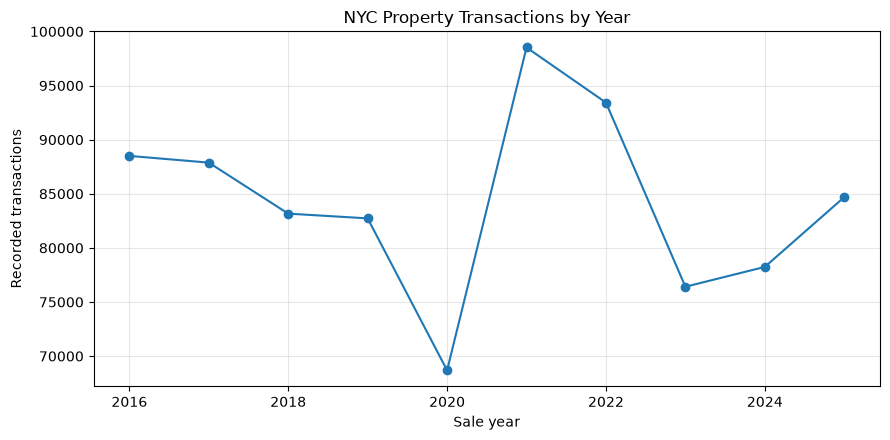

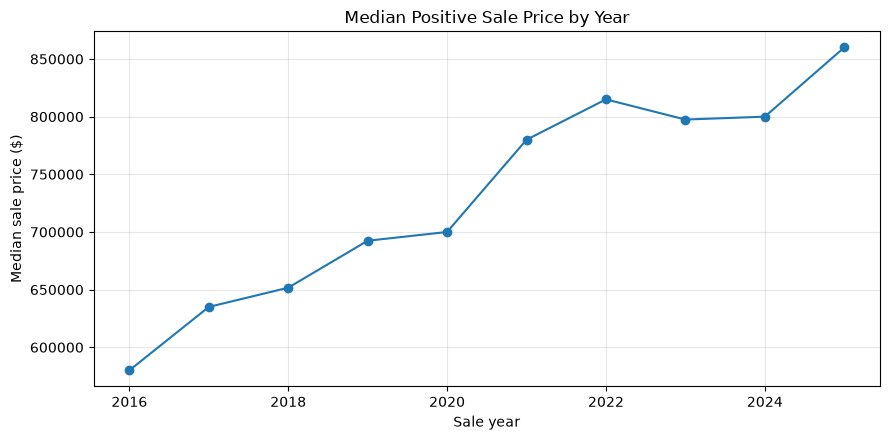

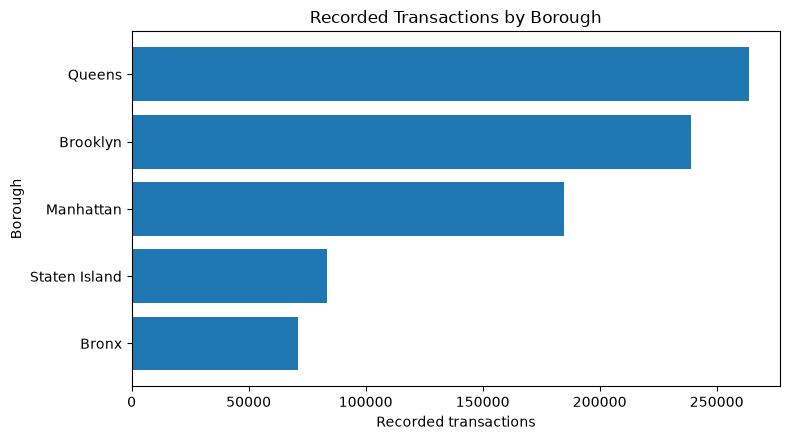

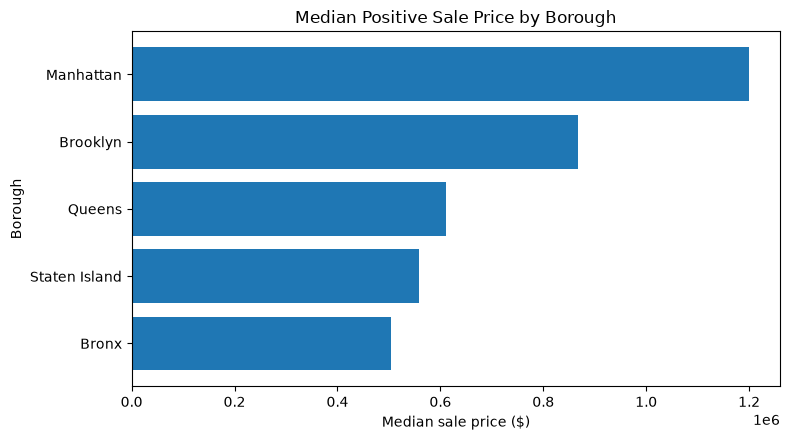

In [14]:
# 1. Transaction activity by year (all recorded transactions)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sales_by_year["SALE YEAR"], sales_by_year["TRANSACTION COUNT"], marker="o")
ax.set_title("NYC Property Transactions by Year")
ax.set_xlabel("Sale year")
ax.set_ylabel("Recorded transactions")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Median positive sale price by year
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(value_by_year["SALE YEAR"], value_by_year["MEDIAN_SALE_PRICE"], marker="o")
ax.set_title("Median Positive Sale Price by Year")
ax.set_xlabel("Sale year")
ax.set_ylabel("Median sale price ($)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Transaction volume by borough (all recorded transactions)
fig, ax = plt.subplots(figsize=(8, 4.5))
borough_plot = sales_by_borough.sort_values("TRANSACTION COUNT")
ax.barh(borough_plot["BOROUGH NAME"], borough_plot["TRANSACTION COUNT"])
ax.set_title("Recorded Transactions by Borough")
ax.set_xlabel("Recorded transactions")
ax.set_ylabel("Borough")
plt.tight_layout()
plt.show()

# 4. Median positive sale price by borough
fig, ax = plt.subplots(figsize=(8, 4.5))
borough_price_plot = borough_value.sort_values("MEDIAN SALE PRICE")
ax.barh(borough_price_plot["BOROUGH NAME"], borough_price_plot["MEDIAN SALE PRICE"])
ax.set_title("Median Positive Sale Price by Borough")
ax.set_xlabel("Median sale price ($)")
ax.set_ylabel("Borough")
plt.tight_layout()
plt.show()

## Key Analytical Findings

Use the tables and charts above to summarize the observed patterns. The points below are descriptive findings, not causal explanations.

1. **Transaction activity varies over time.** Activity was highest in 2016–2017, declined through 2020, rebounded in 2021, and partially recovered by 2025.

2. **Transaction volume and cash-based value are different measures.** Use all records for activity counts and positive-price records for price comparisons.

3. **Queens and Brooklyn account for the highest transaction volumes**, while Manhattan has the highest median positive sale price among the five boroughs.

4. **Property type is associated with transaction value.** Some commercial and specialized categories have higher median prices than many residential categories; transaction counts should be considered alongside medians.

5. **Neighborhood price comparisons require sample-size context.** The 500-positive-price-transaction threshold helps avoid ranking neighborhoods based on very small samples.

6. **Properties with more reported units tend to have higher median sale prices in these records.** This is an association and may reflect differences in property type and location.

7. **Property age does not show a simple linear relationship with median transaction value.**

8. **The share of `$0` sale-price records rises over the study period**, making it important to distinguish overall transfer activity from cash-based price metrics.

9. **The dataset does not identify unique buyers or buyer intent.** Changes in transaction count or property mix do not prove changes in the number of buyers or their preferences.

## Business Implications

The analysis can help stakeholders identify where transaction activity is concentrated, which property categories have high activity versus high median transaction values, and how cash-based price measures differ from overall transfer counts.

Potential uses include:
- selecting boroughs or neighborhoods for deeper review;
- comparing high-volume property types with high-median-price property types;
- monitoring transaction activity and the share of `$0` transfers over time.

These are descriptive signals for further investigation, not forecasts or evidence of causation.

## Methodology and Limitations

- `$0` sale-price records are included in transaction activity counts and excluded from cash-price comparisons.
- Median sale price is used because sale prices are highly skewed.
- The 500-positive-price-transaction threshold is used only for selected comparisons.
- Square-footage fields contain a high proportion of zeros in this dataset, so size-based findings are not included in the main conclusions.
- The data does not provide buyer demographics, buyer intent, financing terms, or property condition.
- Findings describe recorded property transactions and associations; they do not identify unique buyers or explain why a transaction occurred.